# EDA \(Exploratory Data Analysis\)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy
from scipy import stats

## 1\. Memuat Data dan Melihat Gambaran Awal

In [2]:
df = pd.read_csv("/work/osteoporosis.csv")

In [3]:
df = df.drop(columns="Id")

In [4]:
df.shape

(1958, 15)

In [5]:
df.head()

,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1


In [6]:
df.tail()

,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
1953,19,Female,Normal,Yes,African American,Normal,Adequate,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,NaN,Yes,0
1954,23,Female,Postmenopausal,Yes,Caucasian,Underweight,Low,Insufficient,Active,No,NaN,NaN,Corticosteroids,No,0
1955,34,Female,Postmenopausal,No,African American,Underweight,Low,Sufficient,Sedentary,No,NaN,Hyperthyroidism,NaN,No,0
1956,25,Male,Postmenopausal,No,African American,Normal,Low,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,Yes,0
1957,26,Female,Postmenopausal,No,African American,Underweight,Adequate,Sufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Age                  1958 non-null   int64 
 1   Gender               1958 non-null   object
 2   Hormonal Changes     1958 non-null   object
 3   Family History       1958 non-null   object
 4   Race/Ethnicity       1958 non-null   object
 5   Body Weight          1958 non-null   object
 6   Calcium Intake       1958 non-null   object
 7   Vitamin D Intake     1958 non-null   object
 8   Physical Activity    1958 non-null   object
 9   Smoking              1958 non-null   object
 10  Alcohol Consumption  970 non-null    object
 11  Medical Conditions   1311 non-null   object
 12  Medications          973 non-null    object
 13  Prior Fractures      1958 non-null   object
 14  Osteoporosis         1958 non-null   int64 
dtypes: int64(2), object(13)
memory usage: 229.6+ KB


Penjelasan :

Memuat data osteoporosis yang kemudian menghapus kolom id karena tidak digunakan, lalu melihat 5 baris pertama dan 5 baris terakhir dengan menggunakan head\(\), tail\(\)\. Selain itu, melakukan pengecekan cek tipe data tiap kolom denga menggunakan info\(\)\.

## 2\. Cek Kualitas Data

In [8]:
print("Missing Value pada Kolom")
print(df.isnull().sum())

Missing Value pada Kolom
Age                      0
Gender                   0
Hormonal Changes         0
Family History           0
Race/Ethnicity           0
Body Weight              0
Calcium Intake           0
Vitamin D Intake         0
Physical Activity        0
Smoking                  0
Alcohol Consumption    988
Medical Conditions     647
Medications            985
Prior Fractures          0
Osteoporosis             0
dtype: int64


In [9]:
print(f"Jumlah duplikat: {df.duplicated().sum()}")

Jumlah duplikat: 4


Penjelasan : 

Berdasarkan pengecekan dalam missing value diperoleh pada Alkohol Comsumption diperoleh nilai yang kosong 988, Medical Conditions dengan nilai yang kosong 647, dan Medications nilai kosong 985\. Selain itu, dilakukan pengecekan jumlah baris yang berulang sebanyak 4\.

## 3\. Statistik Deskriptif

In [10]:
columns_categorical = ["Gender", "Hormonal Changes", "Family History", "Race/Ethnicity", "Body Weight", "Calcium Intake", "Vitamin D Intake", "Physical Activity", "Smoking", "Alcohol Consumption", "Medical Conditions", "Medications", "Prior Fractures"]
columns_numerical = ["Age"]

### Variabel Numerik

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1958.0,39.101124,21.355424,18.0,21.0,32.0,53.0,90.0
Osteoporosis,1958.0,0.500000,0.500128,0.0,0.0,0.5,1.0,1.0


### Variabel Kategorikal

In [12]:
for column in columns_categorical:
    print(f"Column: {column}")
    print(df[column].value_counts())
    print("-------------------")


Column: Gender
Gender
Male      992
Female    966
Name: count, dtype: int64
-------------------
Column: Hormonal Changes
Hormonal Changes
Normal            981
Postmenopausal    977
Name: count, dtype: int64
-------------------
Column: Family History
Family History
No     998
Yes    960
Name: count, dtype: int64
-------------------
Column: Race/Ethnicity
Race/Ethnicity
African American    681
Caucasian           646
Asian               631
Name: count, dtype: int64
-------------------
Column: Body Weight
Body Weight
Normal         1027
Underweight     931
Name: count, dtype: int64
-------------------
Column: Calcium Intake
Calcium Intake
Low         1004
Adequate     954
Name: count, dtype: int64
-------------------
Column: Vitamin D Intake
Vitamin D Intake
Sufficient      1011
Insufficient     947
Name: count, dtype: int64
-------------------
Column: Physical Activity
Physical Activity
Active       1021
Sedentary     937
Name: count, dtype: int64
-------------------
Column: Smoking
Sm

Penjelasan :

Melakukan statistik deskriptif dengan menggunakan pada variabel numerik dengan menggunakan fungsi describe\(\) untuk mengecek nilai count, min, max, mean, std, percentile 25%, 50%, 75%\. Selain itu, melakukan value\_counts\(\) pada variabel yang kategorikal\.

## 4\. Visualisasi Univariat

## Variabel Numerik 

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


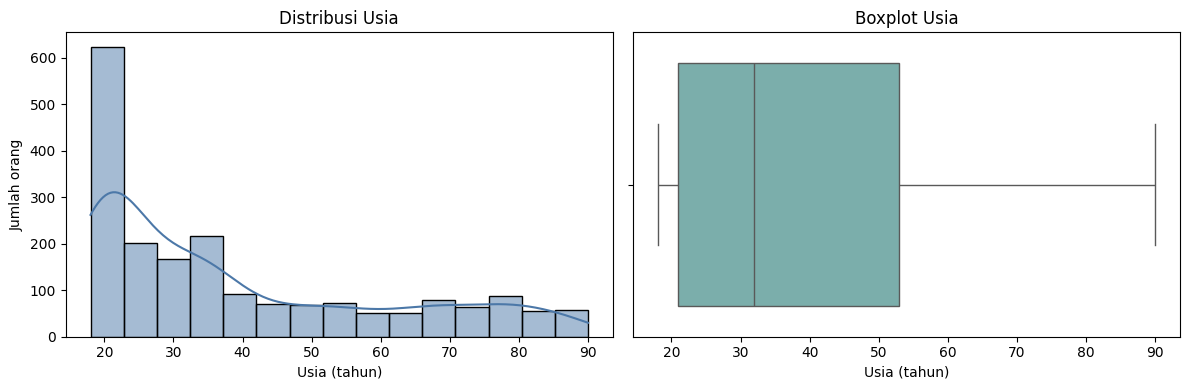

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Age"], bins=15, kde=True, color="#4C78A8", ax=axes[0])
axes[0].set_title("Distribusi Usia")
axes[0].set_xlabel("Usia (tahun)")
axes[0].set_ylabel("Jumlah orang")

sns.boxplot(x=df["Age"], color="#72B7B2", ax=axes[1])
axes[1].set_title("Boxplot Usia")
axes[1].set_xlabel("Usia (tahun)")
plt.tight_layout()
plt.show()

Penjelasan :

Dari visualisasi data variabel numerik univariat dapat  disimpulkan bahwa  mayoritas responden berada  rentang umur 20an dan median berada di rentang 30an\.

## Variabel Kategorikal 

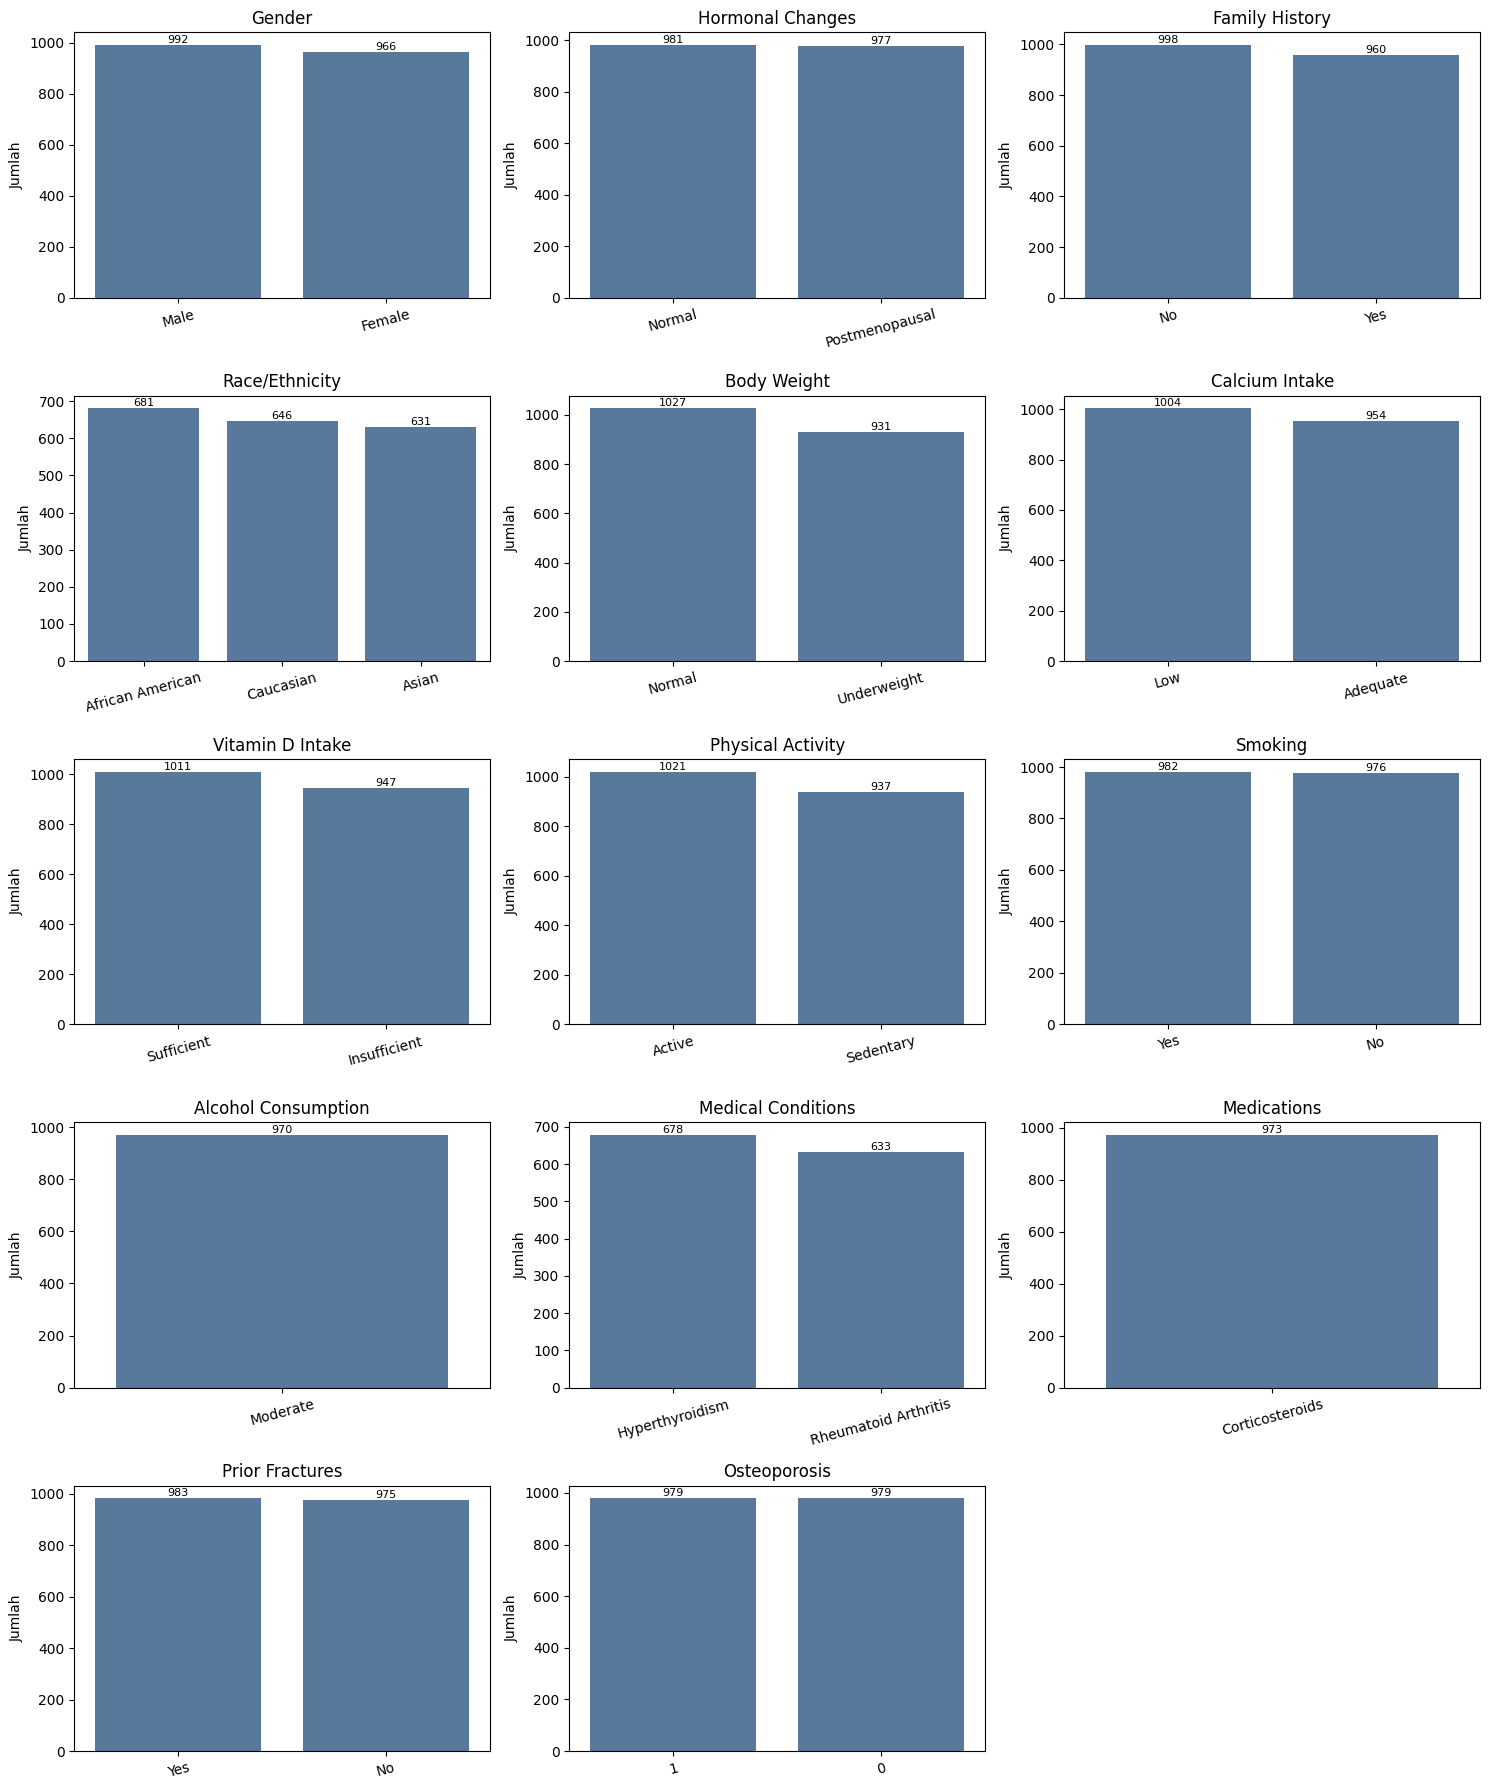

In [16]:
kolom_kat = df.select_dtypes(exclude="number").columns.tolist() + ["Osteoporosis"]

fig, axes = plt.subplots(5, 3, figsize=(15, 18))
for ax, kolom in zip(axes.flat, kolom_kat):
    urutan = df[kolom].value_counts().index
    sns.countplot(data=df, x=kolom, order=urutan, color="#4C78A8", ax=ax)
    ax.set_title(kolom)
    ax.set_xlabel("")
    ax.set_ylabel("Jumlah")
    ax.tick_params(axis="x", rotation=15)
    for container in ax.containers:
        ax.bar_label(container, fontsize=8)
for ax in axes.flat[len(kolom_kat):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

Penjelasan:

Berdasarkan diagram batang di atas, dapat disimpulkan sebaran kategori pada setiap atribut sebagai berikut\. Atribut Gender didominasi oleh kategori Male, sebagian besar responden tidak memiliki riwayat keluarga \(Family History\), mayoritas memiliki asupan vitamin D yang cukup \(Vitamin D Intake\), dan sebagian besar aktif secara fisik \(Physical Activity\)\. Sementara itu, atribut Prior Fractures, Osteoporosis, dan Smoking memiliki sebaran yang relatif seimbang antarkategori\.

## 5\. Mendeteksi dan Menangani Outlier

### IQR \(Interquartile Range\)

In [17]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = df[(df["Age"] < batas_bawah) | (df["Age"] > batas_atas)]

print(f"Batas bawah: {batas_bawah:.2f}")
print(f"Batas atas : {batas_atas:.2f}")
print(f"Jumlah outlier: {len(outlier)} ({len(outlier)/len(df):.1%})")

Batas bawah: -27.00
Batas atas : 101.00
Jumlah outlier: 0 (0.0%)


Penjelasan :  

Setelah melakukan deteksi outlier  menggunakan  metode IQR  dan dapat disimpulkan bahwa Variabel numerikal  tidak memiliki outlier\.

## 6\. Analisis Bivariat \(dua variabel\)

/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


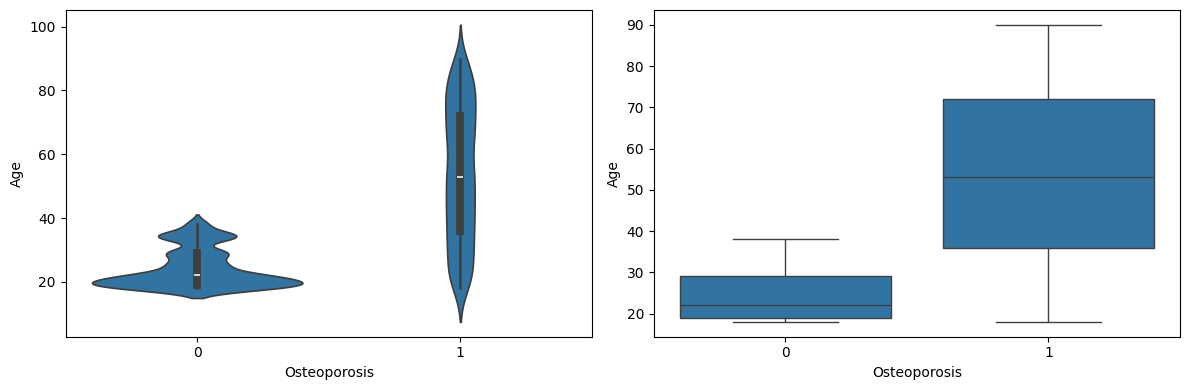

In [66]:
from scipy.stats import chi2_contingency, mannwhitneyu
for k in ["Alcohol Consumption", "Medical Conditions", "Medications"]:
    df[k] = df[k].fillna("Tidak ada")

# Kategorikal vs numerik: Age vs Osteoporosis 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.violinplot(data=df, x="Osteoporosis", y="Age", inner="box", ax=axes[0])
sns.boxplot(data=df, x="Osteoporosis", y="Age", ax=axes[1])
plt.tight_layout(); plt.show()

Penjelasan :  

Pada bagian ini, dilakukannya analasis bivariat untuk mengamati perbedaan distribusi usia \(Age\) berdasarkan status osteoporosis \(Osteoporosis\)\. Sebelum visualisasi dibuat, kolom Alcohol Consumption, Medical Condition, dan Medications diisi dengan nilai "Tidak ada" pada data yang kosong \(missing value\)\. Proses ini bertujuan untuk data kosong pada ketiga kolom tersebut mempunyai tabel yang konsisten, tapi ini tidak otomatis membuktikan bahwa responden memang tidak mengonsumsi alkohol, tidak memiliki kondisi medis, atau tidak menggunakan obat\. 

Selanjutnya, kode membuat dua visualisasi menggunakan library Seaborn, yaitu violin plot dan boxplot\. Violin plot digunakan untuk melihat bentuk distribusi dan kepadatan usia pada setiap kelompok status osteoporosis\. Sementara itu boxploat digunakan untuk membandingkan median, rentang antarkuartil \(IQR\), dan kemungkinan pencilan \(outlier\) usia pada masing masing kelompok\.

Kedua grafik disusun berdampingan menggunakan plt\.subplots \(1, 2, figsize=\(12, 4\)\) agar perbandingan distribusi lebih mudah dilakukan\. Parameter inner="box" pada violin plot menampilkan ringaksan yang bentuknya box di dalam distribusi\. Fungsi plt\.tight\_layout\(\) mengatur tata letak agar elemen grafik tidak saling bertumpuk, sedangkan plt\.show\(\) menampilkan hasil visualisasi\.

Mann-Whitney p = 1.28e-209
                  fitur  cramers_v  p_value
4           Body Weight      0.035    0.124
11          Medications      0.033    0.148
7     Physical Activity      0.018    0.415
6      Vitamin D Intake      0.016    0.469
8               Smoking      0.015    0.498
12      Prior Fractures      0.014    0.527
1      Hormonal Changes      0.014    0.527
10   Medical Conditions      0.012    0.863
0                Gender      0.011    0.619
3        Race/Ethnicity      0.008    0.946
5        Calcium Intake      0.003    0.892
2        Family History      0.001    0.964
9   Alcohol Consumption      0.001    0.964


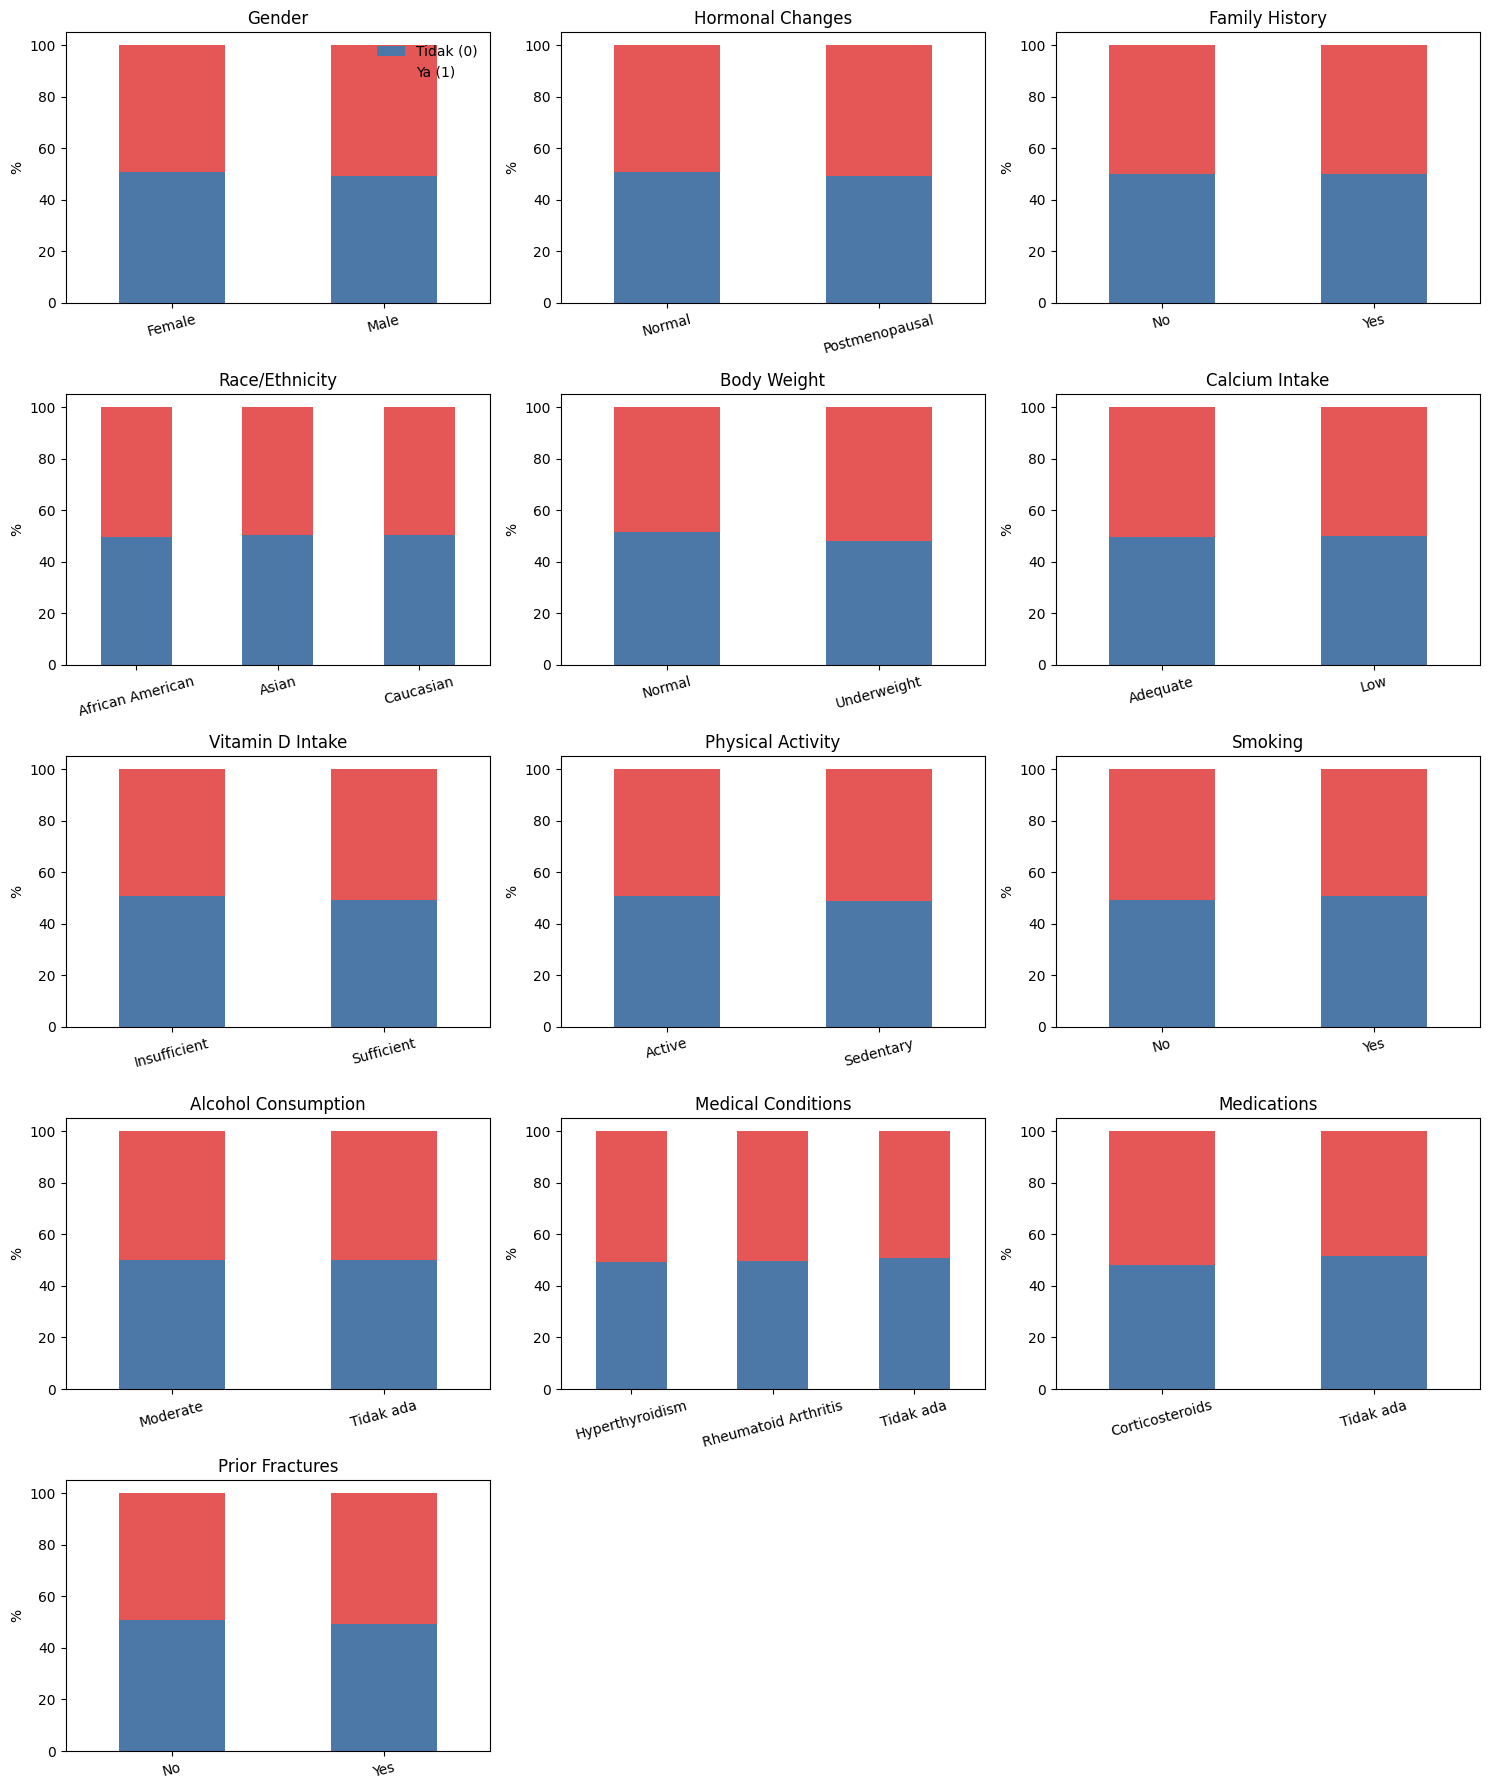

In [64]:
# uji statistik (Age tidak normal, jadi pakai Mann-Whitney)
u, p = mannwhitneyu(df.loc[df.Osteoporosis == 0, "Age"],
                    df.loc[df.Osteoporosis == 1, "Age"])
print(f"Mann-Whitney p = {p:.3g}")

# Kategorikal vs kategorikal: tiap fitur vs Osteoporosis 
kategorikal = [c for c in df.columns if c not in ["Age", "Osteoporosis"]]

# crosstab + chi-square + Cramér's V
hasil = []
for c in kategorikal:
    ct = pd.crosstab(df[c], df["Osteoporosis"])
    chi2, p, _, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    hasil.append({"fitur": c, "cramers_v": v, "p_value": p})
print(pd.DataFrame(hasil).sort_values("cramers_v", ascending=False).round(3))

# stacked bar (proporsi) untuk semua fitur
fig, axes = plt.subplots(5, 3, figsize=(15, 18))
for ax, c in zip(axes.flat, kategorikal):
    pd.crosstab(df[c], df["Osteoporosis"], normalize="index").mul(100).plot(
        kind="bar", stacked=True, ax=ax, color=["#4C78A8", "#E45756"], legend=False)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=15)
for ax in axes.flat[len(kategorikal):]:
    ax.set_visible(False)
axes.flat[0].legend(["Tidak (0)", "Ya (1)"], frameon=False)
plt.tight_layout(); plt.show()

Penjelasan :   
Pada bagian ini,  menunjukan hasi uji hubungnan antara tiap atribut dengan status osteoporosis\.
Menggunakan Mann\-whitney p = 1\.28e\-209 <0\.05 ini digunakan untuk mengukur aitrbut numerikal seperti age\. hal ini menunjukan bahwa usia merupakan faktor yang berhubungan  kuat dengan osteoporosis
Menggunakan Tabel crammer V dan p\_value digunakan untuk uji atribut kategorikal\.
\-crammers\_v untuk mengukur  seberapa kuat hubungannya, dari 0 sampai 1, Angka 0 berarti  tidak ada hubungan sama sekali , 1 berarti hubungan nya sangat kuat, pada seluruh  atribut  kategorikal menunjukan nilai yang sangat kecil\(0,001\-0,035\) 
\-p\_value menunjukan apakah hubungan nya  nyata atau cuma kebetulan, disini  dapat dilihat p value nya semuanya \> 0,05\. sehingga tidak ada hubungan yang signifikan antara atribut kategorikal dan status osteoporosis\.


Grafik :  
Dibuat sebuah stacked bar chart untuk setiap variabel kategorikal\. Fungsi pd\.crosstab dengan normalize="indec" menghitung proporsi setiap status osteoporosis dalam masing\-masing kategori, kemudian mengalikan semuanya dengan 100 agar dapat ditampilkan dalam persentase\.
Grafik disusun dalam kisi berukuran 5 x 3 untuk memudahkan perbandingan pola antar variabel\. Setiap batang menunjukkan komposisi responden tanpa osteoporosis dan dengan osteoporosis pada kategori tertentu, Legenda digunakan untuk membedakan kedua status, sedangkan label sumbu dan judul sudah disesuaikan dengan nama variabel yang ada\. Visualisasi stacked bar mengonfirmasi hal ini: proporsi osteoporosis pada setiap kategori variabel berada di kisaran 50%\. Dengan demikian, di antara seluruh variabel yang diamati, usia merupakan satu\-satunya faktor yang berhubungan kuat dengan osteoporosis dalam dataset ini\.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=03a5eb1b-4fa7-4299-b4b4-8fc0cc8fc75b' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>